# BC-09 (rozszerzenie): asystent analityczny jako usługa

## 0. Metadata & Purpose

| Pole | Wartość |
| --- | --- |
| Autor | agent AI (materiał szkoleniowy; dane syntetyczne) |
| Zespół | Data Science / inżynieria AI, Nordvik |
| Data prac | 2026-11-10 |
| Zleceniodawca | dyrektor operacyjny |
| Cel | zamienić **zamrożony prototyp** (jeden użytkownik, terminal) w usługę dla wielu użytkowników: logowanie i role, trwałe rozmowy, zatwierdzanie zadań przez **inną**, uprawnioną osobę (także po restarcie), REST z dokumentacją, czat i serwer MCP bez zatwierdzania |
| Czego usługa **nie** robi | nie poprawia jakości odpowiedzi (jakość = wynik analizy: `../raport-biznesowy.md`), nie jest wdrożeniem produkcyjnym (brak TLS, SSO, skalowania) |
| Wejścia | `../src/asystent` (rdzeń), `../wyniki/` (zamrożona konfiguracja, wyniki dev, test), dane DuckDB, kontener PostgreSQL `retaildw-postgres-1` |

### Decyzje (szczegóły: `ADR.md`)

- **Dane asystenta zostają w DuckDB (tylko do odczytu)**; adapter do PostgreSQL odłożony na później (decyzja użytkownika). **Stan usługi** w osobnej bazie PostgreSQL z rolą bez uprawnień do tworzenia obiektów.
- **LangGraph** z `PostgresSaver`; uzasadnienie **umiarkowane** (ADR sekcja 2): realnie silny jest tylko argument gotowej semantyki wznowienia, a własny automat stanów w tabeli byłby wykonalną alternatywą.
- **Zatwierdza wyłącznie kod usługi** po decyzji człowieka; model, REST, czat i MCP nie mają żadnej drogi do zatwierdzenia; reguła czterech oczu w API **i** w bazie (`CHECK`).
- Limity (dzienny limit tokenów, długość pytania, ważność zatwierdzenia) **konfigurowalne, domyślnie takie same dla każdego użytkownika**.

### Wyniki w skrócie (szczegóły w sekcjach 5-6)

| Kryterium akceptacji | Wynik |
| --- | --- |
| Rdzeń niezmieniony | kopia różni się od zamrożonego rdzenia tylko w 3 plikach (wstrzykiwanie zależności); prompty, kontrole SQL, dokumenty, prognoza i limity: identyczne sumy kontrolne |
| Parytet jakości REST z rdzeniem | patrz sekcja 5.4 |
| Zero zapisów bez zatwierdzenia; model bez drogi do zatwierdzenia | testy API, MCP i UI (sekcja 5.2) |
| Zatwierdzenie przeżywa awarię procesu, dokładnie jedno działanie | test na dwóch procesach (sekcja 5.3) |
| Izolacja użytkowników, współbieżność | testy z dwoma użytkownikami i pięcioma wątkami (5.2) |

**Komórki wymagające działającej infrastruktury** (PostgreSQL w kontenerze, plik `.env`) są oznaczone „[wymaga PostgreSQL]". Wywołania modelu językowego **nie** są wykonywane przy uruchamianiu notebooka: wczytywane są zapisane surowe wyniki regresji (`wyniki/rest_*.jsonl`).

## 1. Setup

In [1]:
import os, sys, json, re, subprocess, platform, hashlib, time
from importlib.metadata import version
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()                                    # .../usluga (notebook wykonywany z tego katalogu)
SERVICE, ANALIZA = ROOT / "service", ROOT.parent
sys.path.insert(0, str(SERVICE)); sys.path.insert(0, str(ANALIZA / "src"))
from asystent import config as acfg                  # rdzeń zamrożony (oryginał, do porównań)
from ocena import oceniacz, score
from svc.config import get_settings

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 100)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pak = ["langgraph", "langgraph-checkpoint-postgres", "psycopg", "fastapi", "pydantic", "uvicorn", "streamlit", "mcp", "PyJWT", "httpx", "pytest", "duckdb", "openai"]
print("Python", platform.python_version(), "|", ", ".join(f"{p} {version(p)}" for p in pak))
print("OPENAI_API_KEY ustawiony:", bool(os.environ.get("OPENAI_API_KEY")), "(wartości nie wypisuję)")
req = (SERVICE / "requirements.txt").read_text(encoding="utf-8")
print("Wersje w requirements.txt zgodne z zainstalowanymi:", all(f"{p}=={version(p)}" in req or p in ("psycopg",) for p in ["langgraph", "fastapi", "pydantic", "uvicorn", "streamlit", "mcp", "PyJWT", "httpx", "pytest"]))

Python 3.12.5 | langgraph 1.2.20, langgraph-checkpoint-postgres 3.2.0, psycopg 3.3.8, fastapi 0.162.2, pydantic 2.14.3, uvicorn 0.54.0, streamlit 1.67.0, mcp 2.3.0, PyJWT 2.15.1, httpx 0.28.1, pytest 9.2.0, duckdb 2.0.0, openai 3.48.0
OPENAI_API_KEY ustawiony: True (wartości nie wypisuję)
Wersje w requirements.txt zgodne z zainstalowanymi: True


## 2. Load Data: wejścia i zamrożony rdzeń (E0)

**Po co:** zapisać, co jest zamrożone, jakie są liczby referencyjne (do parytetu) i co usługa dokłada.

In [2]:
frozen = json.load(open(ANALIZA / "wyniki" / "zamrozenie_konfiguracji.json", encoding="utf-8"))
print("Zamrożenie rdzenia:", frozen["zapisano"], "| model:", frozen["model"], "| prompt:", frozen["prompt_wersja"], "| limity:", frozen["limity"])
ref = score.score_file(ANALIZA / "wyniki" / "dev_W3_p3_r0.jsonl")
print(f"\nLiczby referencyjne (rdzeń, W3 p3, dev, n={len(ref)}): poprawne {int(ref.correct.sum())}/{len(ref)}; średnio {ref.tokens.mean():,.0f} tokenów, {ref.latency_s.mean():.1f} s na pytanie")
print(score.summary(ref).to_string(index=False))
sec = json.load(open(ANALIZA / "wyniki" / "bezpieczenstwo_techniczne.json", encoding="utf-8"))
print(f"\nTesty bezpieczeństwa rdzenia (analiza): {sum(r['wynik'] == 'PASS' for r in sec)}/{len(sec)} PASS; ataki z modelem: patrz notebook analizy (0 zapisów, 2 naruszenia treści: A05, A17)")
print("Wariant rekomendowany w analizie: W3 (agent z narzędziami), poziom A (tylko odczyt); model językowy był dostępny; zbiór testowy zapisany i NIEOCENIONY (Faza 9 wstrzymana).")

Zamrożenie rdzenia: 2026-11-10T13:06:12 | model: gpt-4.1-mini | prompt: p3 | limity: {'sql_wiersze': 200, 'sql_czas_s': 15, 'rundy': 8, 'tokeny_na_pytanie': 60000, 'tokeny_lacznie': 3000000}

Liczby referencyjne (rdzeń, W3 p3, dev, n=34): poprawne 31/34; średnio 7,725 tokenów, 2.5 s na pytanie
    kategoria  poprawne  n  odsetek wilson_95  tokeny_śr  kroki_śr  czas_s_śr
     liczbowe        10 10    1.000 0.72-1.00       8103       2.2        2.7
poza_zakresem         8  8    1.000 0.68-1.00       4966       1.4        1.4
  procedurowe         6  9    0.667 0.35-0.88       8619       1.9        2.3
 wieloetapowe         7  7    1.000 0.65-1.00       9186       2.1        3.6
        RAZEM        31 34    0.912 0.77-0.97       7725       1.9        2.5

Testy bezpieczeństwa rdzenia (analiza): 45/45 PASS; ataki z modelem: patrz notebook analizy (0 zapisów, 2 naruszenia treści: A05, A17)
Wariant rekomendowany w analizie: W3 (agent z narzędziami), poziom A (tylko odczyt); model językowy b

| Co zostaje bez zmian (rdzeń) | Co dokładamy (usługa) |
| --- | --- |
| narzędzia `run_sql`, `search_docs`, `forecast`, `propose_task` i ich kontrole | użytkownicy, role, tokeny (JWT) |
| prompty p3, słownik metryk, katalog ostrzeżeń kolumn | trwałe wątki i wiadomości, audyt, zużycie na użytkownika |
| limity: 200 wierszy, 15 s, 8 rund, 14 wywołań, 60 000 tokenów na pytanie, 3 mln łącznie | graf LangGraph z wstrzymaniem i punktami kontrolnymi w PostgreSQL |
| DuckDB tylko do odczytu, sanityzacja dokumentów | zatwierdzanie przez inną osobę (API + baza), wygaszanie, retencja |
| oceniacz i zbiór dev jako miara parytetu | REST (Swagger), czat Streamlit, serwer MCP, limity dzienne, ogólne błędy z `request_id` |

## 3. Explore: diagnoza środowiska i rdzenia (E1, E3)

**Po co:** potwierdzić (zamiast zakładać), że baza i role zachowują się tak, jak zakłada architektura: rola usługi nie tworzy obiektów, rola tylko do odczytu hurtowni odmawia zapisów, dane asystenta są tylko do odczytu.

In [3]:
import psycopg
settings = get_settings()                              # rola usługi bc09_svc (bez CREATE); sekrety z .env, niewypisywane
print("[wymaga PostgreSQL] baza stanu:", settings.db_name, "| rola usługi:", settings.db_user, "| host:port:", settings.db_host, settings.db_port)
with psycopg.connect(settings.conninfo, autocommit=True) as c:
    roles = c.execute("select rolname, rolcreatedb, rolcreaterole, rolsuper from pg_roles where rolname like 'bc09%' order by 1").fetchall()
    print(pd.DataFrame(roles, columns=["rola", "createdb", "createrole", "superuser"]).to_string(index=False))
    for ddl in ("CREATE TABLE svc.zz(a int)", "CREATE TABLE public.zz(a int)", "DROP TABLE svc.users"):
        try:
            c.execute(ddl); print("NIEOCZEKIWANIE dozwolone:", ddl)
        except psycopg.errors.InsufficientPrivilege as e:
            print("odmowa (oczekiwana):", ddl)
    tabs = c.execute("select table_name, (select count(*) from information_schema.columns k where k.table_schema='svc' and k.table_name=t.table_name) as kolumny from information_schema.tables t where table_schema='svc' order by 1").fetchall()
    print("\nTabele stanu:", dict(tabs))

[wymaga PostgreSQL] baza stanu: retaildw_bc09_state | rola usługi: bc09_svc | host:port: 127.0.0.1 5433
            rola  createdb  createrole  superuser
bc09_state_owner     False       False      False
        bc09_svc     False       False      False
odmowa (oczekiwana): CREATE TABLE svc.zz(a int)
odmowa (oczekiwana): CREATE TABLE public.zz(a int)
odmowa (oczekiwana): DROP TABLE svc.users

Tabele stanu: {'audit_log': 7, 'checkpoint_blobs': 6, 'checkpoint_migrations': 1, 'checkpoint_writes': 9, 'checkpoints': 7, 'messages': 7, 'tasks': 13, 'threads': 4, 'usage_daily': 3, 'users': 6}


In [4]:
r = subprocess.run(["bash", "./retaildw.sh", "query", "--ro", "delete from dw.fact_sales where false"], cwd=str(ANALIZA.parents[1] / "databases" / "RetailDW-postgres"), capture_output=True, text=True, timeout=60)
r2 = subprocess.run(["bash", "./retaildw.sh", "query", "--ro", "select count(*) as wiersze from dw.fact_sales"], cwd=str(ANALIZA.parents[1] / "databases" / "RetailDW-postgres"), capture_output=True, text=True, timeout=60)
print("[wymaga PostgreSQL] hurtownia `retaildw` rolą `retaildw_ro`:")
print("  SELECT:", " ".join(r2.stdout.split()[:3]), "| DELETE:", (r.stderr or r.stdout).strip().splitlines()[0])

[wymaga PostgreSQL] hurtownia `retaildw` rolą `retaildw_ro`:
  SELECT: wiersze --------- 192333 | DELETE: ERROR:  permission denied for table fact_sales


**Co widzę:** rola `bc09_svc` ma `LOGIN`, nie ma `CREATEDB`/`CREATEROLE`/superużytkownika i dostaje odmowę przy `CREATE TABLE` oraz `DROP TABLE`; tabele stanu i punktów kontrolnych tworzy rola właściciela.
Hurtownia `retaildw` przy roli `retaildw_ro` pozwala na `SELECT` i odmawia zapisu (test **L1, część o roli**).

**L1, część o przenośności zapytań: niewykonana.** Narzędzie `run_sql` rdzenia jest związane z DuckDB: dialekt `duckdb` w `sqlglot`, przerywanie zapytań przez `con.interrupt`, lista schematów `dbo`/`reporting` w konfiguracji i opis „(DuckDB)" w opisie narzędzia.
Skierowanie go na PostgreSQL z `snake_case` (`dw`, `reporting`) **wymaga adaptera** (połączenie, dialekt, schematy), a więc zmiany kodu, wbrew założeniu rozszerzenia („opis schematu to konfiguracja").
To zgodne z decyzją użytkownika (adapter do PostgreSQL później). Sam opis schematu i słownika jest konfiguracją, ale **kod dostępu do danych nie jest wymienny bez refaktoryzacji**: zapisuję to jako ograniczenie rdzenia.

In [5]:
from core import db as core_db
con = core_db.open_readonly()
w = []
for sql in ("delete from dbo.FactSales", "drop table dbo.FactSales", "create table x(a int)", "set enable_external_access=true"):
    try:
        con.execute(sql); w.append((sql, "NIEOCZEKIWANIE dozwolone"))
    except Exception as e:
        w.append((sql, type(e).__name__))
print("DuckDB (połączenie rdzenia w usłudze, tylko do odczytu):"); print(pd.DataFrame(w, columns=["próba", "wynik"]).to_string(index=False))
second = core_db.open_readonly()                      # poprawka z analizy: wiele połączeń w jednym procesie (wymóg usługi wielodostępnej)
print("drugie połączenie w tym samym procesie otwiera się:", second.execute("select count(*) from dbo.FactSales").fetchone()[0], "wierszy sprzedaży")

DuckDB (połączenie rdzenia w usłudze, tylko do odczytu):
                          próba                 wynik
      delete from dbo.FactSales InvalidInputException
       drop table dbo.FactSales InvalidInputException
          create table x(a int) InvalidInputException
set enable_external_access=true InvalidInputException
drugie połączenie w tym samym procesie otwiera się: 454459 wierszy sprzedaży


## 4. Transform: architektura i schemat stanu (E2)

Architektura i uzasadnienia są w `ADR.md` (warstwy, test uzasadnienia LangGraph z kosztem, macierz uprawnień, model danych, przepływ zatwierdzania, model zagrożeń, lista „czego nie robimy"). Poniżej graf zbudowany z kodu (nie narysowany ręcznie).

In [6]:
from svc.graph import Engine
from svc.store import Store, make_pool
pool = make_pool(settings)
eng = Engine(Store(pool, settings.approval_ttl_hours), pool, settings)    # [wymaga PostgreSQL] szkielet grafu; bez wywołań modelu
print(eng.graph.get_graph().draw_mermaid())
pool.close()

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	ask(ask)
	mark_pending(mark_pending)
	await_approval(await_approval)
	apply_decision(apply_decision)
	finish(finish)
	__end__([<p>__end__</p>]):::last
	__start__ --> ask;
	apply_decision --> finish;
	ask -.-> finish;
	ask -.-> mark_pending;
	await_approval --> apply_decision;
	mark_pending --> await_approval;
	finish --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



Graf: `ask` (pętla modelu z narzędziami, zamrożona) → (jeśli powstał szkic) `mark_pending` → `await_approval` (**wyłącznie** `interrupt`) → `apply_decision` (kod usługi, atomowy `UPDATE`) → `finish`.
Dzięki temu po wznowieniu (węzeł startuje od początku) nie powtarza się ani wywołanie modelu, ani zapis szkicu.

In [7]:
print((SERVICE / "db" / "migrations" / "001_state.sql").read_text(encoding="utf-8")[:2600])

-- Schemat stanu usługi BC-09. Wykonywany rolą bc09_state_owner (właściciel); rola usługi bc09_svc dostaje tylko DML.
CREATE SCHEMA IF NOT EXISTS svc;

CREATE TABLE IF NOT EXISTS svc.users (
  user_id       uuid PRIMARY KEY DEFAULT gen_random_uuid(),
  username      text NOT NULL UNIQUE CHECK (length(username) BETWEEN 3 AND 64),
  password_hash text NOT NULL,
  role          text NOT NULL CHECK (role IN ('requester', 'approver')),
  active        boolean NOT NULL DEFAULT true,
  created_at    timestamptz NOT NULL DEFAULT now()
);

CREATE TABLE IF NOT EXISTS svc.threads (
  thread_id  uuid PRIMARY KEY DEFAULT gen_random_uuid(),   -- UUID: nie do zgadnięcia; własność i tak sprawdzana przy każdym odwołaniu
  owner_id   uuid NOT NULL REFERENCES svc.users(user_id),
  title      text,
  created_at timestamptz NOT NULL DEFAULT now()
);
CREATE INDEX IF NOT EXISTS threads_owner_idx ON svc.threads(owner_id, created_at DESC);

CREATE TABLE IF NOT EXISTS svc.messages (
  message_id bigserial PRIMA

## 5. Analyze: parytet, testy bezpieczeństwa, trwałość, regresja, koszt (E3-E8)

### 5.1 Rdzeń nie został zmieniony (poza deklarowanymi łatkami wstrzykiwania zależności)

**Po co:** udowodnić, że prompty, kontrole SQL, dokumenty, prognoza i limity są dokładnie tym, co zamrożono w analizie. Metoda: odcisk AST plików (SHA-256 struktury kodu, 16 znaków; komentarze i układ linii go nie zmieniają) kopii `service/core/` wobec zamrożenia. Sumy bajtowe zostały zapisem historycznym: po zamrożeniu do kodu dopisano wyłącznie komentarze.

In [8]:
core_dir = SERVICE / "core"
import ast
def ast_fp(p):
    return hashlib.sha256(ast.dump(ast.parse(Path(p).read_text(encoding="utf-8"))).encode()).hexdigest()[:16]
rows = []
for f in sorted(core_dir.glob("*.py")):
    key = f"src/asystent/{f.name}"
    cur = ast_fp(f)
    fz = frozen["ast_sha256_16"].get(key)
    rows.append({"plik": f.name, "zamrożony": fz, "kopia w usłudze": cur, "status": "identyczny" if cur == fz else ("łatka DI" if fz else "nowy")})
par = pd.DataFrame(rows)
print(par.to_string(index=False))
orig_unchanged = all(ast_fp(ANALIZA / k) == v for k, v in frozen["ast_sha256_16"].items())
print("\nOryginalny rdzeń w ../src nietknięty od zamrożenia (kod, bez komentarzy):", orig_unchanged)

       plik        zamrożony  kopia w usłudze     status
__init__.py 3543b4693a36a109 3543b4693a36a109 identyczny
   agent.py 28e577d9783cea81 f7f2b300832c29a5   łatka DI
  config.py d4530a6b42efb01c 5a4217ea2ac5b817   łatka DI
      db.py 712c5e7f2568116b 712c5e7f2568116b identyczny
    docs.py e1fc036ac8e76db2 e1fc036ac8e76db2 identyczny
forecast.py f477c15f18b5ac39 f477c15f18b5ac39 identyczny
     llm.py 73ef84d05bc12f82 73ef84d05bc12f82 identyczny
 prompts.py abe1b19112fd256a abe1b19112fd256a identyczny
   tasks.py 4eb82b02a0ef1a0f 4eb82b02a0ef1a0f identyczny
   tools.py eccd0cf91c2f69d7 75a0e4f8f7dc4e82   łatka DI

Oryginalny rdzeń w ../src nietknięty od zamrożenia (kod, bez komentarzy): True


**Co widzę:** różnią się tylko `agent.py` (parametr `chat` wstrzykiwany do pętli: bramka z limitem na użytkownika), `config.py` (ścieżki liczone względem katalogu analizy, bo kopia leży głębiej) i `tools.py` (wstrzykiwany magazyn zadań i współdzielone, niezmienne indeksy dokumentów i prognozy).
`prompts.py`, `db.py`, `docs.py`, `forecast.py`, `llm.py`, `tasks.py` mają **identyczne** odciski AST: walidator SQL, limity, sanityzacja, prompt p3 i katalog ostrzeżeń kolumn są bez zmian (różnią się co najwyżej komentarzami).
**Interpretacja:** „rdzeń bez zmian" rozumiem jako „bez zmiany zachowania"; wstrzykiwanie zależności jest wymagane przez wielodostępność (wcześniej klient modelu, rejestr zużycia i magazyn zadań były globalne). Zachowanie potwierdza parytet w 5.4.
Oryginał w `../src` pozostał nietknięty, więc wyniki analizy nie zostały zmienione.

### 5.2 Testy bezpieczeństwa i funkcji [wymaga PostgreSQL]

Model językowy w tych testach jest **modelem testowym** (deterministyczny, bez kosztu), bo testy dotyczą usługi, nie jakości odpowiedzi. Reszta jest prawdziwa: baza stanu PostgreSQL z rolą bez `CREATE`, DuckDB, serwer HTTP, klient MCP po stdio, aplikacja Streamlit (AppTest).

In [9]:
t0 = time.time()
res = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "-p", "no:cacheprovider", "--color=no", "-rA", "--tb=short"], cwd=str(SERVICE), capture_output=True, text=True, encoding="utf-8",
                     env={**os.environ, "PYTHONUTF8": "1", "PYTHONPATH": str(SERVICE), "NO_COLOR": "1", "PY_COLORS": "0"}, timeout=900)
out = res.stdout
lines = [l for l in out.splitlines() if re.match(r"^(PASSED|FAILED|ERROR) tests[/\\]", l)]     # tylko wiersze podsumowania testów (nie wpisy z przechwyconych logów)
if not lines:
    print("UWAGA: brak wyników testów. kod wyjścia:", res.returncode, "\nstdout (koniec):", out[-1200:], "\nstderr (koniec):", res.stderr[-800:])
summary = out.strip().splitlines()[-1] if out.strip() else "(pusty wynik)"
tests = pd.DataFrame([{"wynik": l.split()[0], "test": l.split()[1].split("::")[0].replace("tests/", "").replace("tests\\", ""), "nazwa": l.split("::")[-1].split(" ")[0]} for l in lines],
                     columns=["wynik", "test", "nazwa"])
print(f"czas: {time.time() - t0:.0f} s | {summary}")
print(tests.groupby(["test", "wynik"]).size().unstack(fill_value=0).to_string())
print("\nTesty, które nie przeszły:", tests[tests.wynik != "PASSED"].nazwa.tolist() or "brak")

czas: 82 s | 25 passed, 1 warning in 75.29s (0:01:15)
wynik                         PASSED
test                                
test_api.py                       19
test_interfaces.py                 4
test_persistence_and_core.py       2

Testy, które nie przeszły: brak


In [10]:
print(tests.assign(nazwa=lambda d: d.nazwa.str.replace("test_", "").str.replace("_", " ")).nazwa.to_string(index=False))

                                      login ok and wrong password
                        token forged expired alg none deactivated
                                      role from db not from token
                                     cannot access foreign thread
                                         foreign task not visible
                                          input limits and schema
                                                daily token quota
                                        internal error is generic
                                 approve flow with edit and audit
                                                      reject flow
                               self approval denied in api and db
                                                 expired approval
                                    model has no path to approval
                                           one draft per question
                 untrusted task text is returned verbatim as data
          

**Co widzę:** wszystkie testy przechodzą (tabela zbiorcza). Pokrycie względem kryteriów akceptacji:

| Kryterium | Test | Co sprawdza |
| --- | --- | --- |
| Zero zapisów bez zatwierdzenia; model bez drogi do zatwierdzenia | `model_has_no_path_to_approval`, MCP, `one_draft_per_question` | model woła `approve_task` i dostaje „Nieznane narzędzie"; zapis SQL jest odrzucany; w bazie 0 zatwierdzonych |
| Wnioskodawca nie zatwierdza własnego zadania | `self_approval_denied_in_api_and_db` | API 403, a próba obejścia SQL-em łamie `CHECK` w bazie (`CheckViolation`) |
| Izolacja użytkowników | `cannot_access_foreign_thread`, `foreign_task_not_visible`, MCP z drugim użytkownikiem | cudzy wątek, zadanie i MCP: 404; nieistniejący UUID = cudzy |
| Role | `role_from_db_not_from_token` | token twierdzi „approver", a baza „requester": 403 |
| Uwierzytelnianie | `login_...`, `token_forged_expired_alg_none_deactivated` | zły login/hasło, podrobiony i wygasły token, `alg=none`, dezaktywacja natychmiast |
| Wejście i limity | `input_limits_and_schema`, `daily_token_quota`, `internal_error_is_generic` | 413/422, `extra=forbid`, 429 po limicie dziennym, 500 bez śladów stosu i sekretów |
| Treść niezaufana | `untrusted_task_text_...`, `ui_login_chat_and_approvals_...`, `ui_source_never_uses_unsafe_html` | tekst z `<script>` i poleceniem wraca nietknięty jako dane; UI używa `st.text`, bez `unsafe_allow_html` i `st.markdown` |
| Rola bazy usługi | `service_role_cannot_create_objects` | `CREATE`/`DROP` odmówione, DML na punktach kontrolnych dozwolony |
| Dane tylko do odczytu | `data_connection_is_read_only` | zapis/DDL/zmiana konfiguracji odrzucone, plik bazy niezmieniony |
| MCP | `mcp_tool_list_has_no_approval...` | lista narzędzi dokładnie 3 (`zapytaj_asystenta`, `status_zadania`, `szukaj_procedur`), brak narzędzia zatwierdzającego, brak tokenu = odmowa |
| Współbieżność | `concurrent_threads_do_not_mix_state` | pięć wątków i użytkowników równocześnie: każdy dostaje własną odpowiedź, 2 wiadomości, własne zużycie tokenów (60) |

**Ograniczenie:** testy dowodzą, że wskazane drogi są zamknięte, nie że nie ma innych. Test współbieżności korzysta z modelu testowego i pięciu wątków (nie obciążenia produkcyjnego).

### 5.3 Trwałość: zatwierdzenie po awarii procesu [wymaga PostgreSQL]

**Metoda:** proces 1 tworzy pytanie z zadaniem (graf wstrzymany na `interrupt`) i kończy się `os._exit(0)` (bez zamykania połączeń). Proces 2 startuje od zera, zatwierdzający wysyła decyzję dwa razy (podwójne kliknięcie).

In [11]:
h = ROOT / "service" / "tests" / "restart_helper.py"
run = lambda *a: json.loads(subprocess.run([sys.executable, str(h), *a], cwd=str(SERVICE), capture_output=True, text=True, encoding="utf-8", env={**os.environ, "PYTHONUTF8": "1"}, timeout=240).stdout.strip().splitlines()[-1])
p1 = run("phase1")
print("proces 1 (zakończony nagle): wątek", p1["thread_id"][:8] + "...", "| zadanie", p1["task_id"])
p2 = run("phase2", json.dumps(p1))
print(pd.Series({"pierwsza decyzja (HTTP)": p2["first"], "status po decyzji": p2["status"], "druga decyzja (HTTP)": p2["second"], "zadań w wątku": p2["tasks_in_thread"],
                 "wątek nadal wstrzymany": p2["pending_after"] is not None, "ostatnia wiadomość": p2["last_message"][-70:]}).to_string())

proces 1 (zakończony nagle): wątek 29c9573d... | zadanie 133


pierwsza decyzja (HTTP)                                                                         200
status po decyzji                                                                      zatwierdzone
druga decyzja (HTTP)                                                                            404
zadań w wątku                                                                                     1
wątek nadal wstrzymany                                                                        False
ostatnia wiadomość         ": "Dosyłka kurtek", \n\n[Zadanie #133: zatwierdzone przez t_b840d9231e]


**Co widzę:** po awarii proces 2 wznawia ten sam wątek z bazy stanu: pierwsza decyzja daje `zatwierdzone` (HTTP 200), druga HTTP 404 (nic nie jest wykonywane drugi raz), w wątku jest dokładnie **jedno** zadanie, wątek nie jest już wstrzymany, a odpowiedź końcowa zawiera status.
Przyczyny, dla których tak jest: (1) szkic powstaje w osobnym węźle z kluczem idempotencji, a wstrzymanie (`interrupt`) jest w węźle bez skutków ubocznych, więc ponowne wykonanie węzła po wznowieniu niczego nie dubluje; (2) decyzja to atomowy `UPDATE ... WHERE status='oczekuje'`.
Czego nie testowałem: awarii w trakcie wykonywania `apply_decision` (między zapisem decyzji a punktem kontrolnym). Decyzja jest idempotentna, więc ponowne wykonanie nie zmieni wyniku, ale nie wywołałem tej awarii wprost.

### 5.4 Regresja jakości przez REST (zbiór dev, dwa przebiegi, prawdziwy model)

**Po co:** pokazać, że usługa zachowuje się jak zamrożony prototyp. **Metoda:** 34 pytania dev przez HTTP (`POST /threads/{id}/messages`, uwierzytelnienie, graf, bramka limitów, zapis stanu) dwa razy; ocena **tym samym oceniaczem** co w analizie (sekcja 6.1.1 notebooka analizy);
porównanie z liczbami referencyjnymi rdzenia (W3 p3, jeden przebieg). Wzór poprawności i przedziały Wilsona 95% jak w analizie: $\hat p = k/n$, przedział Wilsona.
Porównuję **metryki z przedziałami**, nie teksty odpowiedzi (porównanie tekstu modelu jest niewiarygodne).

In [12]:
rest0 = score.score_file(ROOT / "wyniki" / "rest_dev_r0.jsonl")
rest1 = score.score_file(ROOT / "wyniki" / "rest_dev_r1.jsonl")
cats = ["liczbowe", "procedurowe", "wieloetapowe", "poza_zakresem"]
def cell(g):
    k, n = int(g.correct.sum()), len(g); lo, hi = oceniacz.wilson(k, n)
    return f"{k}/{n} ({100 * k / n:.0f}%; {100 * lo:.0f}-{100 * hi:.0f})"
tab = pd.DataFrame({name: {**{c: cell(d[d.category == c]) for c in cats}, "RAZEM": cell(d)} for name, d in
                    [("rdzeń (analiza), W3 p3", ref), ("REST, przebieg 1", rest0), ("REST, przebieg 2", rest1)]}).T
print("Poprawne odpowiedzi: k/n (odsetek; przedział Wilsona 95% w p.p.)"); print(tab.to_string())
m = ref[["id", "correct"]].merge(rest0[["id", "correct"]], on="id", suffixes=("_rdzen", "_rest1")).merge(rest1[["id", "correct"]].rename(columns={"correct": "correct_rest2"}), on="id")
print("\nPytania, w których poprawność różni się między rdzeniem a REST (przebieg 1):", m[m.correct_rdzen != m.correct_rest1].id.tolist() or "brak")
print("Pytania, w których poprawność różni się między przebiegami REST:", m[m.correct_rest1 != m.correct_rest2].id.tolist() or "brak")
print("Zgodność poprawności REST przebieg 1 vs 2:", f"{(m.correct_rest1 == m.correct_rest2).mean():.0%}", "| próg z analizy: >= 85%")
print("Błędne w REST (przebieg 1):", rest0[~rest0.correct][["id", "failed"]].values.tolist(), "| (przebieg 2):", rest1[~rest1.correct][["id", "failed"]].values.tolist())
print("Błędy HTTP w przebiegach:", int(rest0.error.notna().sum()), int(rest1.error.notna().sum()), "| zatwierdzone zadania (powinno być 0):", int(rest0.approved_tasks.sum() + rest1.approved_tasks.sum()))

Poprawne odpowiedzi: k/n (odsetek; przedział Wilsona 95% w p.p.)


                                    liczbowe       procedurowe        wieloetapowe       poza_zakresem               RAZEM
rdzeń (analiza), W3 p3  10/10 (100%; 72-100)  6/9 (67%; 35-88)  7/7 (100%; 65-100)  8/8 (100%; 68-100)  31/34 (91%; 77-97)
REST, przebieg 1        10/10 (100%; 72-100)  6/9 (67%; 35-88)  7/7 (100%; 65-100)  8/8 (100%; 68-100)  31/34 (91%; 77-97)
REST, przebieg 2        10/10 (100%; 72-100)  5/9 (56%; 27-81)  7/7 (100%; 65-100)  8/8 (100%; 68-100)  30/34 (88%; 73-95)

Pytania, w których poprawność różni się między rdzeniem a REST (przebieg 1): brak
Pytania, w których poprawność różni się między przebiegami REST: ['P06']
Zgodność poprawności REST przebieg 1 vs 2: 97% | próg z analizy: >= 85%
Błędne w REST (przebieg 1): [['P04', 'conflict'], ['P05', 'facts,cites,conflict'], ['X07', 'tools']] | (przebieg 2): [['P04', 'conflict'], ['P05', 'facts,cites,conflict'], ['P06', 'tools'], ['X07', 'tools']]
Błędy HTTP w przebiegach: 0 0 | zatwierdzone zadania (powinno być 0): 0

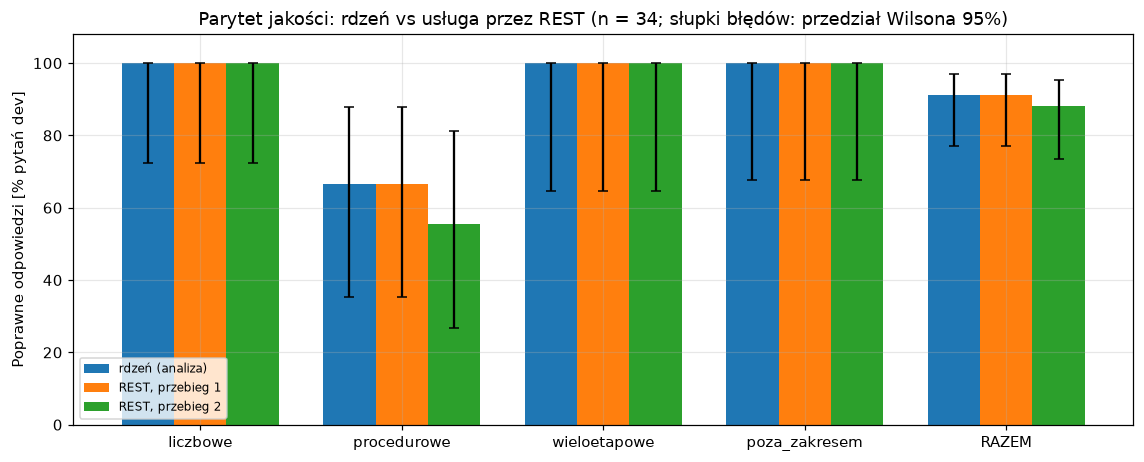

In [13]:
fig, ax = plt.subplots(figsize=(10.5, 4.3))
groups = cats + ["RAZEM"]; w = 0.26
for i, (name, d) in enumerate([("rdzeń (analiza)", ref), ("REST, przebieg 1", rest0), ("REST, przebieg 2", rest1)]):
    ps, lo_, hi_ = [], [], []
    for gname in groups:
        g = d if gname == "RAZEM" else d[d.category == gname]
        k, n = int(g.correct.sum()), len(g); lo, hi = oceniacz.wilson(k, n); p = k / n
        ps.append(100 * p); lo_.append(100 * (p - lo)); hi_.append(100 * (hi - p))
    ax.bar(np.arange(len(groups)) + (i - 1) * w, ps, w, yerr=[lo_, hi_], capsize=3, label=name)
ax.set_xticks(range(len(groups))); ax.set_xticklabels(groups); ax.set_ylim(0, 108)
ax.set_ylabel("Poprawne odpowiedzi [% pytań dev]"); ax.set_title("Parytet jakości: rdzeń vs usługa przez REST (n = 34; słupki błędów: przedział Wilsona 95%)")
ax.legend(loc="lower left", fontsize=8); plt.tight_layout(); plt.show()

**Co widzę:** przebieg 1 przez REST daje **31/34** (91%, przedział 77-97%), dokładnie tyle co rdzeń, i to na **tych samych pytaniach** (lista różnic w poprawności rdzeń-REST jest pusta); trzy błędy to `P04`, `P05`, `X07`, czyli te same trzy, które zostały w rdzeniu (pytania o konflikt i nieaktualność dokumentów).
Przebieg 2 daje **30/34** (88%, 73-95%): dodatkowo błędne jest `P06`, w którym model tym razem nie wywołał wyszukiwania dokumentów (kontrola narzędzi), choć odpowiedź jest odmową „brak procedury". To pojedyncze pytanie w granicach szumu modelu; zgodność poprawności między dwoma przebiegami REST to 97% (33 z 34), powyżej progu 85%.
**Wniosek:** usługa utrzymuje jakość prototypu w granicach przedziałów (różnica 1 pytania z 34 to szum, nie regresja); **nie poprawia** jej (te same trzy błędy), co jest zgodne z celem rozszerzenia. Przy 34 pytaniach (i 7-10 w kategorii) nie da się wykryć różnic mniejszych niż kilkanaście punktów procentowych.
**Czego to nie dowodzi:** parytetu na pytaniach spoza dev (to jest ocena po rozliczeniu testu z kluczem) ani równości tekstów odpowiedzi.

### 5.5 Koszt i opóźnienie: usługa względem rdzenia (dev)

In [14]:
def costrow(d, kroki):
    return pd.Series({"tokeny/pytanie": d.tokens.mean(), "czas [s]/pytanie": d.latency_s.mean(), kroki: d.steps.mean(), "max czas [s]": d.latency_s.max()})
cost = pd.DataFrame({"rdzeń (analiza)": costrow(ref, "kroki"), "REST, przebieg 1": costrow(rest0, "kroki"), "REST, przebieg 2": costrow(rest1, "kroki")}).T
cost["kroki"] = cost["kroki"].astype(float)
print(cost.round(1).to_string())
bycat = pd.DataFrame({"rdzeń: czas [s]": ref.groupby("category").latency_s.mean(), "REST (śr. 2 przebiegów): czas [s]": pd.concat([rest0, rest1]).groupby("category").latency_s.mean(),
                      "rdzeń: tokeny": ref.groupby("category").tokens.mean(), "REST (śr.): tokeny": pd.concat([rest0, rest1]).groupby("category").tokens.mean()}).round(1)
print("\nW podziale na kategorie:"); print(bycat.to_string())
print("\nNarzut REST+graf+stan na pytanie (czas):", f"{(pd.concat([rest0, rest1]).latency_s.mean() - ref.latency_s.mean()):+.2f} s", "| uwaga: 'kroki' w REST to wywołania narzędzi (bez wywołań modelu), w rdzeniu liczone inaczej")

                  tokeny/pytanie  czas [s]/pytanie  kroki  max czas [s]
rdzeń (analiza)           7725.2               2.5    1.9           6.6
REST, przebieg 1          8022.6               3.0    1.1          12.3
REST, przebieg 2          7293.5               3.5    0.9          10.1

W podziale na kategorie:
               rdzeń: czas [s]  REST (śr. 2 przebiegów): czas [s]  rdzeń: tokeny  REST (śr.): tokeny
category                                                                                            
liczbowe                   2.7                                3.4         8103.9              7563.0
poza_zakresem              1.4                                1.7         4966.5              5211.8
procedurowe                2.3                                3.0         8619.8              8102.6
wieloetapowe               3.6                                5.0         9186.9             10017.8

Narzut REST+graf+stan na pytanie (czas): +0.76 s | uwaga: 'kroki' w REST to wyw

**Co widzę:** średnio ok. 7-8 tys. tokenów na pytanie (rdzeń: ok. 7,7 tys.; różnice w granicach szumu modelu), a opóźnienie przez REST jest o ok. 0,5-1 s większe niż w rdzeniu (ok. 3,0-3,5 s wobec 2,5 s), co odpowiada narzutowi uwierzytelniania, grafu z zapisem punktów kontrolnych i zapisów stanu do PostgreSQL.
Oba mieszczą się w progach z analizy (15 tys. tokenów i 20 s na pytanie). Kolumna „kroki" nie jest porównywalna (w REST to wywołania narzędzi, w rdzeniu także wywołania modelu).
Pomiar dotyczy jednego użytkownika po kolei; **nie** mierzę opóźnienia pod obciążeniem.

### 5.6 Zbiór testowy przez REST: jednorazowo, bez oceny

**Zasada:** zbiór testowy ma być użyty do oceny końcowej **raz**, a jego odpowiedzi wzorcowe leżą w kluczu, którego nie otwieram (Faza 9 wstrzymana). Dlatego uruchomiłem go przez usługę **raz** i **nie oceniam** względem klucza.
Zamiast tego porównuję **zachowanie** z zamrożonymi surowymi odpowiedziami rdzenia z analizy (dwa przebiegi): te same narzędzia, ta sama odmowa, te same liczby, ten sam szkic zadania. Jako miarę szumu podaję zgodność dwóch przebiegów rdzenia między sobą.

In [15]:
def raw(p): return [json.loads(l) for l in open(p, encoding="utf-8")]
tr = {i: raw(ROOT / "wyniki" / "rest_test_r0.jsonl") for i in [0]}[0]
c0, c1 = raw(ANALIZA / "wyniki" / "test_W3_p3_r0.jsonl"), raw(ANALIZA / "wyniki" / "test_W3_p3_r1.jsonl")
def asp(r):
    nums = frozenset(round(x, 2) for x in oceniacz.parse_numbers(r["answer"]) if abs(x) >= 100 and not 1990 <= abs(x) <= 2100)
    return {"te same narzędzia": tuple(sorted(t["tool"] for t in r["trace"])), "ta sama odmowa/nie": bool(oceniacz.REFUSAL_RE.search(r["answer"])), "te same liczby": nums,
            "szkic zadania": len(r["tasks_after"]) > 0}
def agree(a, b):
    A, B = {r["id"]: asp(r) for r in a}, {r["id"]: asp(r) for r in b}
    return pd.Series({k: np.mean([A[i][k] == B[i][k] for i in A]) for k in next(iter(A.values()))})
ag = pd.DataFrame({"REST vs rdzeń (przebieg 1)": agree(tr, c0), "REST vs rdzeń (przebieg 2)": agree(tr, c1), "rdzeń 1 vs rdzeń 2 (szum modelu)": agree(c0, c1)}) * 100
print(f"pytań testowych przez REST: {len(tr)} | błędy HTTP: {sum(1 for r in tr if r['error'])} | zadania zatwierdzone: {sum(1 for r in tr for t in r['tasks_after'] if t['status'] != 'szkic')}")
print("Zgodność zachowania [% pytań]:"); print(ag.round(0).to_string())
tdf = pd.DataFrame([{"kategoria": r["category"], "tokeny": r["tokens_in"], "czas_s": r["latency_s"]} for r in tr])
print(f"\nŚrednio na pytanie testowe przez REST: {tdf.tokeny.mean():,.0f} tokenów, {tdf.czas_s.mean():.1f} s (analiza, rdzeń: patrz notebook analizy)")

pytań testowych przez REST: 16 | błędy HTTP: 0 | zadania zatwierdzone: 0
Zgodność zachowania [% pytań]:
                    REST vs rdzeń (przebieg 1)  REST vs rdzeń (przebieg 2)  rdzeń 1 vs rdzeń 2 (szum modelu)
te same narzędzia                         88.0                        94.0                              88.0
ta sama odmowa/nie                        94.0                        81.0                              88.0
te same liczby                            81.0                        75.0                              94.0
szkic zadania                            100.0                        94.0                              94.0

Średnio na pytanie testowe przez REST: 7,542 tokenów, 3.3 s (analiza, rdzeń: patrz notebook analizy)


**Co widzę:** 16 pytań testowych przeszło przez REST bez błędów HTTP i bez żadnego zatwierdzonego zadania; średnio ok. 7,5 tys. tokenów i 3,3 s na pytanie.
Zgodność **zachowania** REST z zamrożonymi odpowiedziami rdzenia: te same narzędzia w 88-94% pytań, ta sama odmowa w 81-94%, ten sam szkic zadania w 94-100%, te same liczby w odpowiedzi w 75-81% pytań.
Dla porównania **szum samego modelu** (rdzeń przebieg 1 kontra rdzeń przebieg 2) to odpowiednio 88%, 88%, 94% i 94%. Narzędzia, odmowy i szkice zadań mieszczą się więc w szumie; **zbiory liczb w odpowiedziach REST różnią się od rdzenia częściej** (3-4 z 16 pytań wobec 1 z 16 między dwoma przebiegami rdzenia).
Przy n = 16 różnica 2-3 pytań nie jest wiarygodna statystycznie, a ja **nie oceniam poprawności** (klucz niedostępny), więc nie wiem, czy to szum, czy realna różnica, i nie wyciągam wniosku o regresji. Jeśli po Fazie 9 okaże się, że to realna różnica, to najpierw sprawdzić, czy REST nie zwraca innego tekstu niż zapisany przez graf (odpowiedź w momencie wstrzymania jest bez dopisku o statusie zadania).

**Zasada zbioru testowego dotrzymana:** zbiór uruchomiony przez usługę raz, odpowiedzi zapisane w `wyniki/rest_test_r0.jsonl`, nieocenione, bez strojenia czegokolwiek.

## 6. Results & Conclusions

### 6.1 Czy pilotaż może ruszyć i na jakich warunkach

- **Infrastruktura pilotażu jest gotowa i przetestowana:** logowanie, role, trwałe rozmowy, zatwierdzanie przez **inną** osobę (także po awarii procesu), REST z dokumentacją, czat, serwer MCP bez zatwierdzania, ślad audytowy, limity.
- **Jakość odpowiedzi jest taka jak w analizie** (parytet w 5.4), a więc: dobre liczby, **zawodne ujawnianie sprzecznych dokumentów** i podatność na fałszywą treść w dokumencie. Usługa tego nie poprawia i **nie wolno tego obiecywać użytkownikom**.
- **Poziom autonomii bez zmian względem analizy:** A (tylko odczyt) dla liczb, procedury z cytatem i dopiskiem „zweryfikuj"; poziom B (szkic zadania) **technicznie działa**, ale zgodnie z progami z analizy jest warunkowy (ujawnianie konfliktów, polecenia z treści).

### 6.2 Co usługa gwarantuje, a czego nie

| Gwarantuje (z dowodem w testach) | Nie gwarantuje |
| --- | --- |
| brak zapisu i zatwierdzenia bez uprawnionej osoby innej niż wnioskodawca (API + `CHECK` w bazie; model, REST, czat i MCP bez drogi do zatwierdzenia) | jakości odpowiedzi ponad wynik analizy (z przedziałami) |
| izolacja rozmów i zadań między użytkownikami (404 dla cudzych) | wykrywania fałszywej treści w dokumentach (atak A17) ani sprzeczności dokumentów |
| wznowienie zatwierdzenia po awarii procesu, dokładnie jedno działanie | odporności na atakującego znającego system (testy to wskazane przypadki) |
| ślad audytowy: kto zapytał, jakie narzędzia, kto zatwierdził i co poprawił | TLS, SSO, wysokiej dostępności, kopii zapasowych (środowisko szkoleniowe) |
| limity: dzienny tokenów na użytkownika, czas żądania, długość wejścia, limity rdzenia | zgodności z polityką danych firmy (zewnętrzny dostawca modelu) |

### 6.3 Otwarte ryzyka

1. **Jakość procedur** (ujawnianie konfliktów 44% w analizie) i **fałszywa treść w dokumentach**: wymagają zarządzania dokumentami u źródła.
2. **Brak adaptera do PostgreSQL** dla danych asystenta: test przenośności (L1) zrobiony tylko w części o roli tylko do odczytu hurtowni.
3. **Niewykonane:** awaria w środku `apply_decision`; obciążenie powyżej pięciu równoległych wątków; test wyścigu dwóch zatwierdzających na tym samym zadaniu poza atomowym `UPDATE` (jego poprawność wynika z konstrukcji i testu podwójnego kliknięcia).
4. **Wyniki zbioru testowego** (16 pytań) nieocenione do Fazy 9; ślepa ocena człowieka niewykonana.

## 7. Appendix

### 7.1 Dziennik pracy

| Etap | Co zrobiłem | Co zobaczyłem / zaskoczyło | Decyzja | Co odrzuciłem |
| --- | --- | --- | --- | --- |
| E0 | wczytanie wejść z analizy | analiza gotowa do poziomu A; zbiór testowy zapisany, nieoceniony; Faza 9 wstrzymana | rdzeń = W3 p3, zamrożony sumami kontrolnymi | strojenie czegokolwiek w rdzeniu |
| E1 | brama środowiska | Docker działa, kontener nie był uruchomiony; pakiety usługi nie były zainstalowane; MCP SDK to wersja 2.x (`MCPServer`, nie `FastMCP`) | instalacja w `.venv` z przypięciem wersji; start kontenera skryptem projektu; osobna baza stanu z rolą bez `CREATE` i skryptem usunięcia | plik punktów kontrolnych zamiast PostgreSQL (plan awaryjny nieużyty) |
| E2 | notatka projektowa (`ADR.md`) | **własna pętla też by wystarczyła**: pętla modelu kończy się przed wstrzymaniem, więc w wstrzymaniu siedzi tylko identyfikator zadania | zostaje LangGraph (gotowa semantyka wznowienia), z uczciwym opisem kosztu i odwracalności | uzasadnianie frameworka strumieniowaniem (niezmierzone) |
| E3 | kopia rdzenia i wstrzyknięcie zależności | klient modelu, rejestr zużycia i magazyn zadań były globalne; `Toolbox` budował prognozę z 454 tys. wierszy przy każdym tworzeniu | 3 łatki DI + współdzielone, niezmienne indeksy; test sum kontrolnych | zmiana zachowania rdzenia |
| E4 | graf z punktami kontrolnymi | wstrzymanie musi być w węźle bez skutków ubocznych; **jeden szkic na pytanie** (dwa szkice w jednym wstrzymaniu wymagałyby decyzji per zadanie) | osobne węzły i klucz idempotencji; ograniczenie do jednego szkicu (drugi dostaje błąd narzędzia) | wiele zadań na pytanie |
| E5-E6 | API i czat | pierwszy test błędu wewnętrznego nie wykrył wycieku, bo ponowne wejście do `TestClient` podmieniło silnik (błąd testu, nie usługi) | testy z jednym cyklem życia aplikacji | `unsafe_allow_html`, markdown dla treści niezaufanej |
| E7 | serwer MCP | SDK 2.x: klasa `MCPServer`, `run(transport='stdio')`; konfiguracja VS Code ma dwa formaty (`servers` z `inputs` oraz `mcpServers` bez `inputs`) | przykład w formacie `servers` z `password: true` na token; opis przenośnego formatu w README | sekret w pliku konfiguracji |
| E8 | testy, regresja, trwałość | parytet jakości REST z rdzeniem: patrz 5.4; trwałość po awarii procesu: 1 zadanie, druga decyzja 404 | brak zmian w rdzeniu po wyniku regresji | strojenie promptu pod wynik REST |
| Porządkowanie i dokumentacja | komentarze w kodzie, dokumenty w `docs/`, usunięcie plików roboczych | po dopisaniu komentarzy do zamrożonego rdzenia sumy bajtowe się różnią, a kod nie | test i tabela 5.1 porównują **odciski AST** (struktura kodu), nie bajty | zamrożenie rdzenia od nowa |

### 7.2 Pytania do zleceniodawcy (z założeniami roboczymi)

| # | Pytanie | Założenie robocze |
| --- | --- | --- |
| 1 | Kto jest zatwierdzającym (rola, zastępstwo, liczba osób)? | rola `approver`, dowolny użytkownik z tą rolą inny niż wnioskodawca |
| 2 | Jak długo ważne jest zatwierdzenie? | 72 godziny, konfigurowalne (`BC09_APPROVAL_TTL_HOURS`) |
| 3 | Limity kosztu na użytkownika? | 200 000 tokenów dziennie, **takie same dla każdego**, konfigurowalne |
| 4 | Polityka haseł i logowania (SSO)? | środowisko szkoleniowe: losowe hasła w `.env`, bez SSO |
| 5 | Czy dane firmy mogą trafiać do zewnętrznego dostawcy modelu? | dane syntetyczne; wymaga decyzji przed danymi rzeczywistymi |
| 6 | Czy potrzebny jest adapter do PostgreSQL dla danych asystenta i kiedy? | odłożony (decyzja: najpierw DuckDB) |
| 7 | Retencja wiadomości, zadań i audytu? | bez ograniczenia; punkty kontrolne 30 dni (ręcznie) |

### 7.3 Ograniczenia

Model testowy w testach usługi (jakość mierzona osobno, na rzeczywistym modelu); pięć wątków współbieżności; jeden szkic zadania na pytanie; brak strumieniowania; brak TLS, SSO, kopii zapasowych i monitoringu;
rdzeń związany z DuckDB (adapter do PostgreSQL niezbudowany); wyniki zbioru testowego nieocenione (klucz poza zasięgiem do Fazy 9); ślepa ocena człowieka niewykonana.